In [ ]:
# Import required libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("bank.csv", sep=";")

print("Dataset loaded successfully!")

print(df.head())

In [ ]:
import pandas as pd

# Read the CSV file
df = pd.read_csv("bank.csv", sep=";")

# Display the first 10 records
print("First 10 Records:")
print(df.head(10))

# Display the last 5 records
print("Last 5 Records:")
print(df.tail(5))


In [ ]:
# Print total number of rows and columns
print("Number of rows and columns:")
print(df.shape)

# Print column names
print("\nColumn names:")
print(df.columns)

# Print datatypes and memory usage
print("\nDataset information:")
df.info()

In [ ]:

# Select numerical columns
columns = ["age", "balance", "day"]

# Calculate statistics for each column
for column in columns:

    print(f"\nStatistics for {column}")
    print("Mean:", df[column].mean())
    print("Median:", df[column].median())
    print("Minimum:", df[column].min())
    print("Maximum:", df[column].max())
    print("Standard Deviation:", df[column].std())


In [ ]:
# Create missing values summary
missing_summary = pd.DataFrame({
    "Total Missing Values": df.isnull().sum(),
    "Percentage Missing": (df.isnull().sum() / len(df)) * 100
})

# Display results
print(missing_summary)

In [ ]:

# ==========================================
# 1. IMPORT PANDAS AND LOAD THE DATASET
# ==========================================

import pandas as pd

df = pd.read_csv("bank.csv", sep=";")

print("Dataset loaded successfully!")
print("Original dataset shape:", df.shape)


# ==========================================
# 2. CHECK FOR DUPLICATE RECORDS
# ==========================================

print("\nChecking duplicate records...")

duplicates = df.duplicated().sum()

print("Number of duplicate records:", duplicates)


# ==========================================
# 3. REMOVE DUPLICATE RECORDS
# ==========================================

df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)


# ==========================================
# 4. CHECK FOR MISSING VALUES
# ==========================================

print("\nChecking missing values...")

missing_summary = pd.DataFrame({
    "Total Missing": df.isnull().sum(),
    "Percentage Missing": (df.isnull().sum() / len(df)) * 100
})

print(missing_summary)


# ==========================================
# 5. HANDLE MISSING VALUES
# ==========================================

# Identify numerical columns
numerical_columns = df.select_dtypes(include="number").columns

# Identify categorical/text columns
categorical_columns = df.select_dtypes(include="object").columns

# Fill numerical missing values using the median
for column in numerical_columns:

    if df[column].isnull().any():

        df[column] = df[column].fillna(df[column].median())


# Fill categorical missing values using the mode
for column in categorical_columns:

    if df[column].isnull().any():

        df[column] = df[column].fillna(df[column].mode()[0])


print("\nMissing values after cleaning:")
print(df.isnull().sum())


# ==========================================
# 6. CORRECT DATA TYPES
# ==========================================

# Convert categorical/text columns to category
df[categorical_columns] = df[categorical_columns].astype("category")

print("\nUpdated data types:")
print(df.dtypes)


# ==========================================
# 7. VERIFY THE CLEANED DATASET
# ==========================================

print("\n========== CLEANING SUMMARY ==========")

print("Final dataset shape:", df.shape)

print("Remaining duplicate records:", df.duplicated().sum())

print("Remaining missing values:", df.isnull().sum().sum())

print("\nDataset information:")
df.info()


# ==========================================
# 8. DISPLAY CLEANED DATA
# ==========================================

print("\nFirst five rows of cleaned dataset:")
print(df.head())


In [ ]:

# ==========================================
# FILTER CUSTOMERS BY ACCOUNT BALANCE
# ==========================================

# Select customers with a balance greater than 1000
filtered_customers = df[df["balance"] > 1000]

# Display the filtered records
print("Customers with a balance above 1000:")

print(filtered_customers)

# Display the total number of matching customers
print("\nTotal matching customers:", len(filtered_customers))


In [ ]:

# ==========================================
# SORT DATASET USING ACCOUNT BALANCE
# ==========================================

# Sort records by balance in descending order
sorted_df = df.sort_values(by="balance", ascending=False)

# ==========================================
# DISPLAY TOP 10 RECORDS
# ==========================================

print("TOP 10 CUSTOMERS WITH HIGHEST BALANCES")
print(sorted_df.head(10))

# ==========================================
# DISPLAY BOTTOM 10 RECORDS
# ==========================================

print("\nBOTTOM 10 CUSTOMERS WITH LOWEST BALANCES")
print(sorted_df.tail(10))


In [ ]:
# Create a summary table
job_summary = df.groupby("job", observed=True).agg(
    Total_Customers=("job", "size"),
    Total_Balance=("balance", "sum"),
    Average_Balance=("balance", "mean")
)

# Display the summary
print(job_summary)

CORRELATION MATRIX
           age  balance   day  duration  campaign  pdays  previous
age       1.00     0.08 -0.02     -0.00     -0.01  -0.01     -0.00
balance   0.08     1.00 -0.01     -0.02     -0.01   0.01      0.03
day      -0.02    -0.01  1.00     -0.02      0.16  -0.09     -0.06
duration -0.00    -0.02 -0.02      1.00     -0.07   0.01      0.02
campaign -0.01    -0.01  0.16     -0.07      1.00  -0.09     -0.07
pdays    -0.01     0.01 -0.09      0.01     -0.09   1.00      0.58
previous -0.00     0.03 -0.06      0.02     -0.07   0.58      1.00

POSSIBLE OUTLIERS
{'age': 38, 'balance': 506, 'day': 0, 'duration': 330, 'campaign': 318, 'previous': 816}


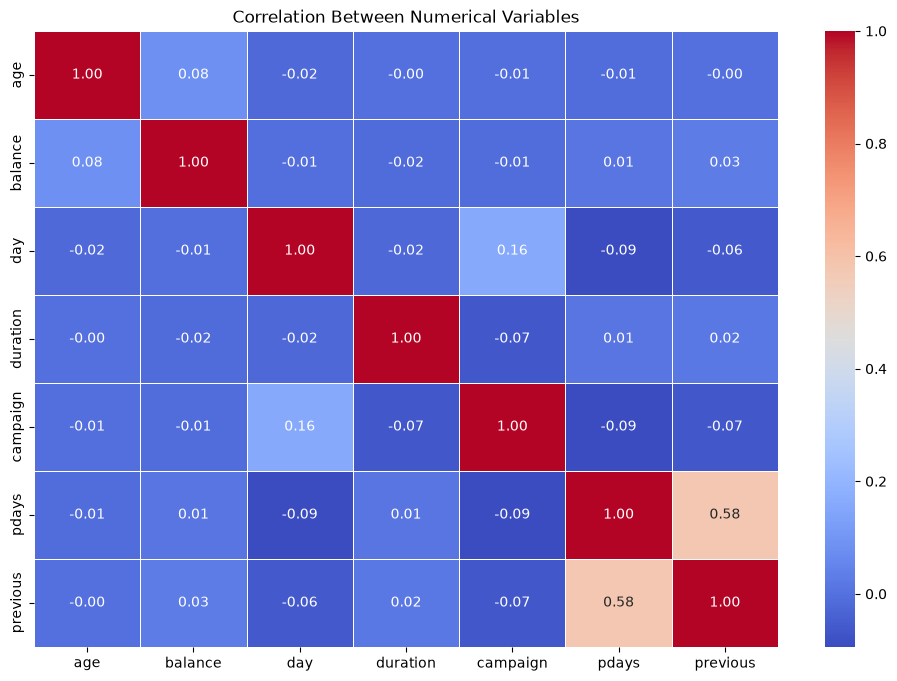

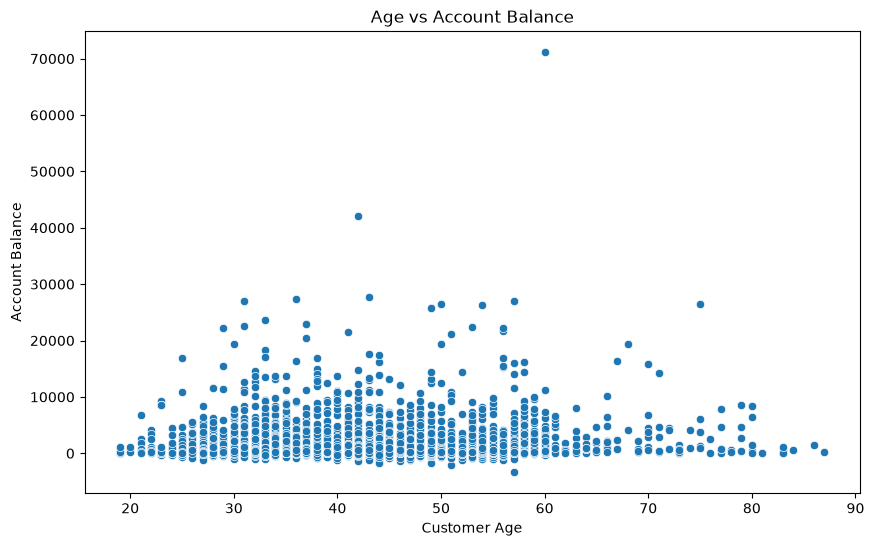

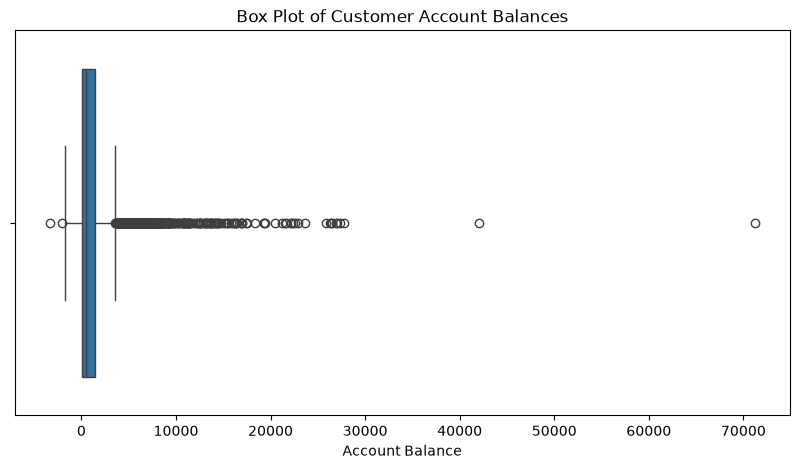

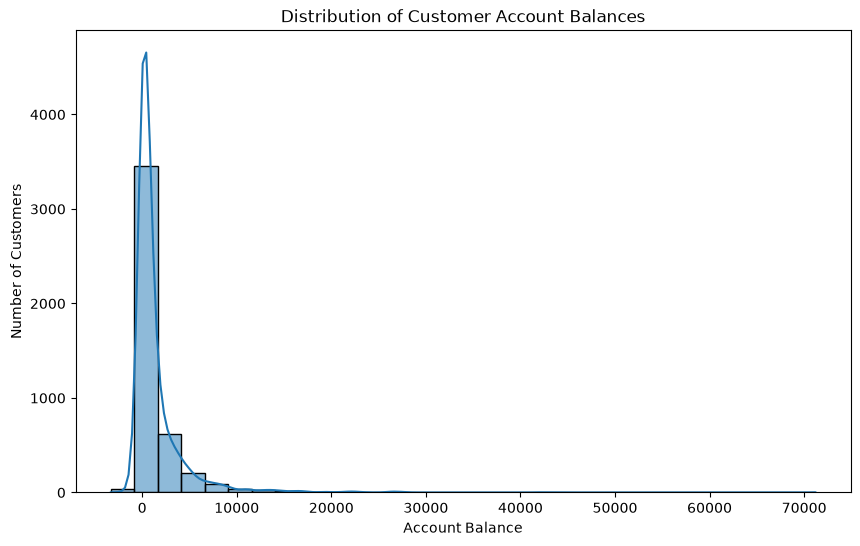

In [6]:

# =================================
# 1. CALCULATE CORRELATIONS
# =================================

# Select numerical columns
numerical_df = df.select_dtypes(include="number")

# Calculate correlation matrix
correlation_matrix = numerical_df.corr()

print("CORRELATION MATRIX")
print(correlation_matrix.round(2))


# =================================
# 2. IDENTIFY POSSIBLE OUTLIERS
# =================================

# Exclude pdays because -1 means not previously contacted
outlier_columns = [
    column for column in numerical_df.columns
    if column != "pdays"
]

outlier_summary = {}

for column in outlier_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ]

    outlier_summary[column] = len(outliers)

print("\nPOSSIBLE OUTLIERS")
print(outlier_summary)


# =================================
# 3. CHART 1: CORRELATION HEATMAP
# =================================

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Numerical Variables")
plt.show()


# =================================
# 4. CHART 2: SCATTER PLOT
# =================================

plt.figure(figsize=(10, 6))

sns.scatterplot(data=df, x="age", y="balance")

plt.title("Age vs Account Balance")
plt.xlabel("Customer Age")
plt.ylabel("Account Balance")
plt.show()


# =================================
# 5. CHART 3: BOX PLOT
# =================================

plt.figure(figsize=(10, 5))

sns.boxplot(x=df["balance"])

plt.title("Box Plot of Customer Account Balances")
plt.xlabel("Account Balance")
plt.show()


# =================================
# 6. CHART 4: HISTOGRAM
# =================================

plt.figure(figsize=(10, 6))

sns.histplot(data=df, x="balance", bins=30, kde=True)

plt.title("Distribution of Customer Account Balances")
plt.xlabel("Account Balance")
plt.ylabel("Number of Customers")
plt.show()


In [26]:
df.to_csv("bank_cleaned.csv", index=False)
print("Cleaned file saved as bank_cleaned.csv")


Cleaned file saved as bank_cleaned.csv


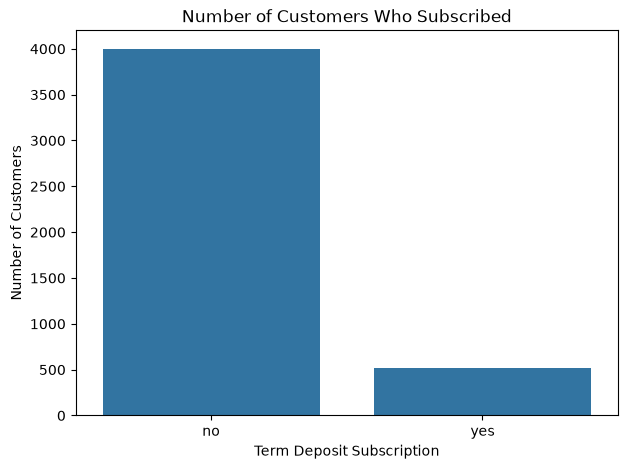

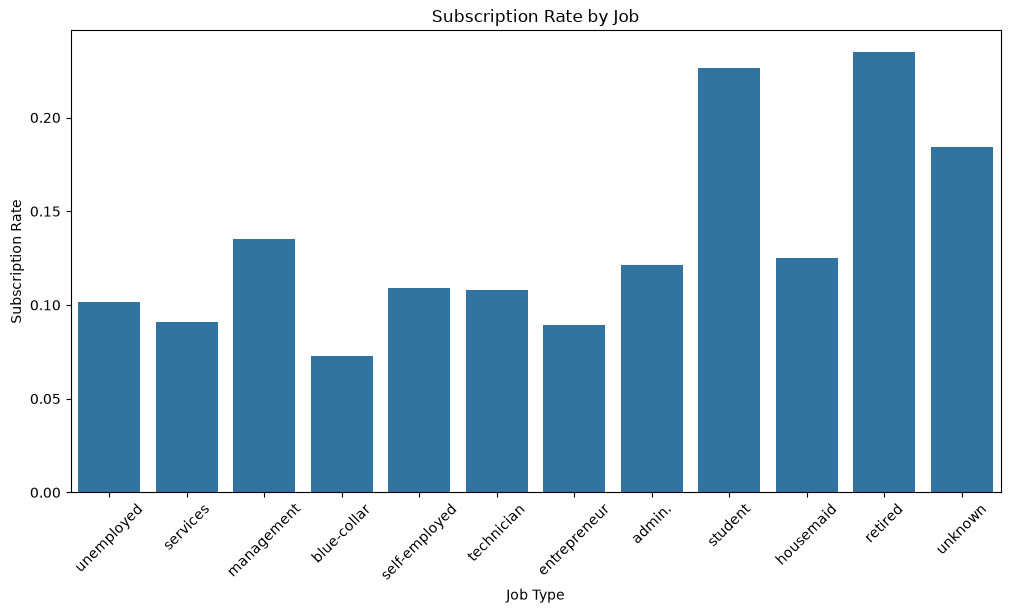

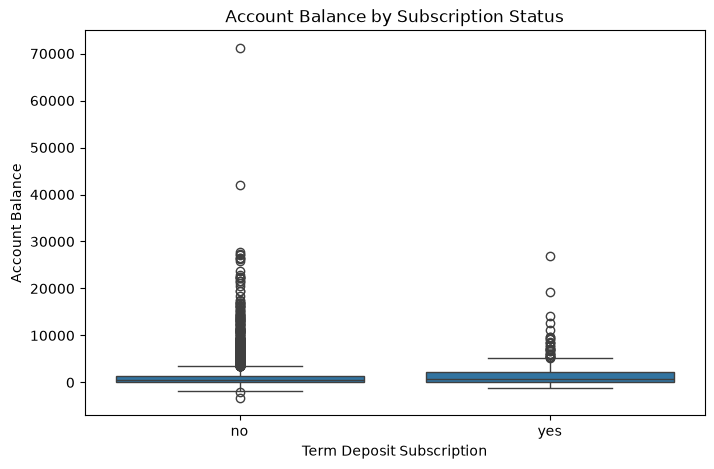

In [5]:



# =================================
# 3. CHART 1: SUBSCRIPTION COUNTS
# =================================

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="y")

plt.title("Number of Customers Who Subscribed")
plt.xlabel("Term Deposit Subscription")
plt.ylabel("Number of Customers")

plt.show()


# =================================
# 4. CHART 2: SUBSCRIPTION BY JOB
# =================================

plt.figure(figsize=(12, 6))

sns.barplot(
    data=df,
    x="job",
    y=df["y"].eq("yes").astype(int),
    errorbar=None
)

plt.title("Subscription Rate by Job")
plt.xlabel("Job Type")
plt.ylabel("Subscription Rate")

plt.xticks(rotation=45)
plt.show()


# =================================
# 5. CHART 3: BALANCE BY SUBSCRIPTION
# =================================

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="y", y="balance")

plt.title("Account Balance by Subscription Status")
plt.xlabel("Term Deposit Subscription")
plt.ylabel("Account Balance")

plt.show()
